In [1]:
import pandas as pd
import matplotlib.pyplot as plt

gen = pd.read_csv("../data/processed/generacion_mensual_tecnologia.csv")
gen["anio"] = gen["mes"].str[:4].astype(int)
gen = gen[gen["anio"] <= 2025]          # solo años completos

# Generación anual por tecnología y participación (%)
anual = gen.pivot_table(index="anio", columns="TipoGeneracion",
                        values="GWh", aggfunc="sum", fill_value=0)
participacion = anual.div(anual.sum(axis=1), axis=0) * 100

print("TWh por tecnología:")
print((anual / 1000).round(1))
print("\n% del total:")
print(participacion.round(1))

TWh por tecnología:
TipoGeneracion  Eolica  Hidraulica  Sin clasificar  Solar  Termica
anio                                                              
2013               0.1        44.2             0.1    0.0     17.8
2014               0.1        44.6             0.1    0.0     19.5
2015               0.1        44.6             0.1    0.0     21.8
2016               0.1        46.8             0.0    0.0     19.1
2017               0.0        57.2             0.2    0.0      9.3
2018               0.0        56.6             0.0    0.0     12.2
2019               0.1        54.4             0.0    0.1     15.5
2020               0.0        49.8             0.0    0.2     19.3
2021               0.1        60.5             0.0    0.3     13.1
2022               0.1        64.3             0.0    0.5     12.0
2023               0.2        59.8             0.0    1.2     19.4
2024               0.1        54.5             0.0    3.3     25.3
2025               0.2        68.1        

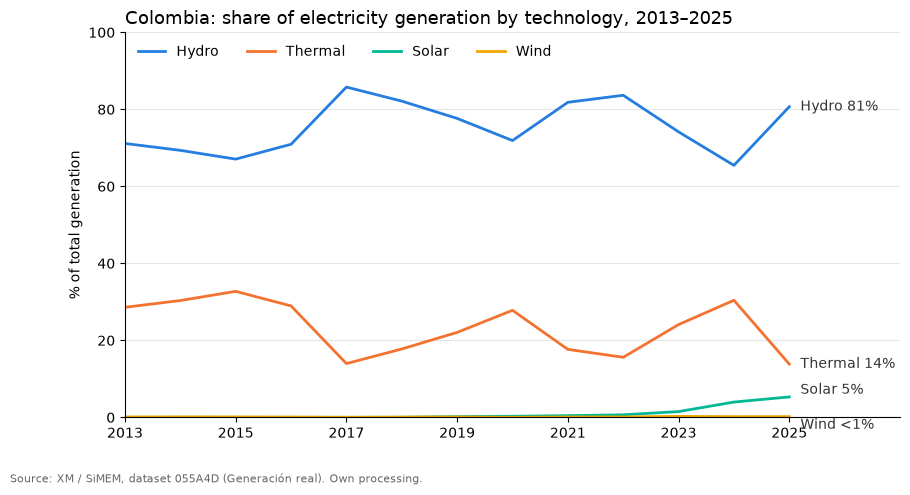

In [4]:
COLORES = {"Hidraulica": "#257de0", "Termica": "#f47230", "Solar": "#00b894", "Eolica": "#f2a600"}
NOMBRES = {"Hidraulica": "Hydro", "Termica": "Thermal", "Solar": "Solar", "Eolica": "Wind"}

fig, ax = plt.subplots(figsize=(10, 5))
for tec, color in COLORES.items():
    serie = participacion[tec]
    ax.plot(serie.index, serie, color=color, linewidth=2, label=NOMBRES[tec])
    valor = serie.iloc[-1]
    texto = f"{NOMBRES[tec]} {valor:.0f}%" if valor >= 1 else f"{NOMBRES[tec]} <1%"
    desplazar = {"Solar": 5, "Eolica": -6}.get(tec, 0)
    ax.annotate(texto, xy=(serie.index[-1], valor), xytext=(8, desplazar),
                textcoords="offset points", va="center", fontsize=10, color="#333333")

ax.set_title("Colombia: share of electricity generation by technology, 2013–2025",
             loc="left", fontsize=13)
ax.set_ylabel("% of total generation")
ax.set_ylim(0, 100)
ax.set_xlim(2013, 2027)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xticks(range(2013, 2026, 2))
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
ax.legend(frameon=False, ncol=4, loc="upper left")
fig.text(0.01, -0.02, "Source: XM / SiMEM, dataset 055A4D (Generación real). Own processing.",
         fontsize=8, color="#666666")

fig.savefig("../figures/01_mix_share_annual.png", dpi=200, bbox_inches="tight")
plt.show()

In [5]:
# Meses de El Niño según NOAA CPC, ONI v6 (ONI >= +0.5, mes central del trimestre).
# Fuente: https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/oni/v6/
EL_NINO = {
    "2014-16": ("2014-10", "2016-05"),
    "2018-19": ("2018-09", "2019-06"),
    "2019-20": ("2019-10", "2020-03"),
    "2023-24": ("2023-05", "2024-04"),
    "2026":    ("2026-04", "2026-08"),   # en curso; valores recientes aún provisionales
}

men = pd.read_csv("../data/processed/generacion_mensual_tecnologia.csv")
mensual = men.pivot_table(index="mes", columns="TipoGeneracion",
                          values="GWh", aggfunc="sum", fill_value=0)
pct = mensual.div(mensual.sum(axis=1), axis=0) * 100
pct.index = pd.PeriodIndex(pct.index, freq="M")

# Etiquetar cada mes con su episodio de El Niño (o "Sin El Niño")
pct["episodio"] = "Sin El Niño"
for nombre, (ini, fin) in EL_NINO.items():
    en_rango = (pct.index >= pd.Period(ini, "M")) & (pct.index <= pd.Period(fin, "M"))
    pct.loc[en_rango, "episodio"] = nombre

print(pct.groupby(pct["episodio"] != "Sin El Niño")[["Hidraulica", "Termica"]].mean().round(1))
print(pct.groupby("episodio")[["Hidraulica", "Termica"]].mean().round(1))

TipoGeneracion  Hidraulica  Termica
episodio                           
False                 78.1     20.4
True                  68.9     29.5
TipoGeneracion  Hidraulica  Termica
episodio                           
2014-16               65.4     34.3
2018-19               79.3     20.4
2019-20               68.4     31.3
2023-24               66.0     31.4
2026                  69.5     22.1
Sin El Niño           78.1     20.4


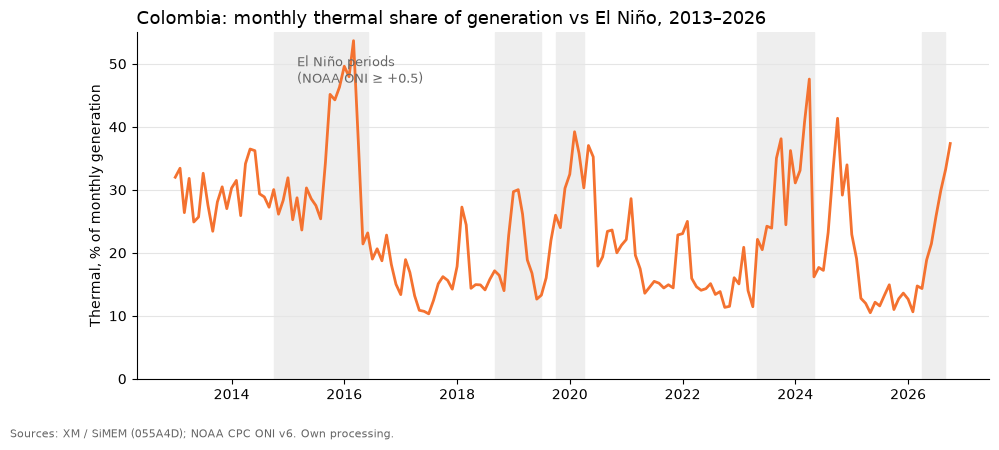

In [6]:
fechas = pct.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 4.5))
for nombre, (ini, fin) in EL_NINO.items():
    ax.axvspan(pd.Period(ini, "M").to_timestamp(), pd.Period(fin, "M").to_timestamp("M"),
               color="#eeeeee", zorder=0)
ax.plot(fechas, pct["Termica"], color="#f47230", linewidth=2)
ax.text(pd.Timestamp("2015-03-01"), 47, "El Niño periods\n(NOAA ONI ≥ +0.5)",
        fontsize=9, color="#666666")

ax.set_title("Colombia: monthly thermal share of generation vs El Niño, 2013–2026",
             loc="left", fontsize=13)
ax.set_ylabel("Thermal, % of monthly generation")
ax.set_ylim(0, 55)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
fig.text(0.01, -0.02, "Sources: XM / SiMEM (055A4D); NOAA CPC ONI v6. Own processing.",
         fontsize=8, color="#666666")
fig.savefig("../figures/02_thermal_share_el_nino.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
termica = pct["Termica"]
filas = []
for nombre, (ini, fin) in EL_NINO.items():
    i, f = pd.Period(ini, "M"), pd.Period(fin, "M")
    antes = termica[(termica.index >= i - 12) & (termica.index < i)]
    ventana = termica[(termica.index >= i) & (termica.index <= f + 3)]   # +3 meses por el retraso
    filas.append({
        "episodio": nombre,
        "térmica 12m antes (%)": antes.mean(),
        "promedio en el episodio (%)": termica[(termica.index >= i) & (termica.index <= f)].mean(),
        "pico (%)": ventana.max(),
        "mes del pico": str(ventana.idxmax()),
    })
efecto = pd.DataFrame(filas).round(1)
efecto["subida del pico (pp)"] = (efecto["pico (%)"] - efecto["térmica 12m antes (%)"]).round(1)
efecto

,episodio,térmica 12m antes (%),promedio en el episodio (%),pico (%),mes del pico,subida del pico (pp)
0,2014-16,30.5,34.3,53.7,2016-03,23.2
1,2018-19,17.1,20.4,30.0,2019-02,12.9
2,2019-20,19.9,31.3,39.2,2020-02,19.3
3,2023-24,14.3,31.4,47.6,2024-04,33.3
4,2026,12.5,22.1,37.4,2026-10,24.9
